In [1]:
import wot
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scanpy as sc
from pathlib import Path
from collections import defaultdict
from scipy import sparse

import sys
from pathlib import Path

_start = Path.cwd().resolve()
_repo_root = next((p for p in [_start, *_start.parents] if (p / "chronopack").exists()), _start)
if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))

from chronopack.trajectories import (
    CalculateTerminalFatesAcrossCells,
    PlotHardClusterMassProportionsOverTime,
    build_transition_matrices,
    cosine_topk_leiden_from_terminal_dist,
    embed_block,
    extract_wot_couplings,
    fate_umap_2x2_scanpy,
    keep_topk,
    mass_retention_plots_and_umap,
    run_wot_transport_workflow,
    read_tmap,
    sparse_adjacency_from_tmats,
    terminal_fates_from_terminal_clusters,
    topk_csr_rows,
)


# Function definitions

## Waddington‑OT (Transport maps)
Following the official [WOT notebooks](https://github.com/broadinstitute/wot/tree/master/notebooks), we compute transport maps between successive time points.
Make sure `adata.obs['time']` (integer or float) exists and reflects the sampling time in *hours/days* used in the Seurat notebook.

In [2]:
adata_hvg = sc.read_h5ad('../output/adata_hvg.1e4-variant.chk0.h5ad')
adata_hvg.obs['time'] = pd.to_numeric(adata_hvg.obs['time'].astype(str))
adata_hvg.X = adata_hvg.layers['corrected'].copy()

TMAP_DIR = '../intmd/tmaps.SingleCell.1e4/'

wot_out = run_wot_transport_workflow(
    adata_hvg,
    tmap_dir=TMAP_DIR,
    ot_model_kwargs=dict(epsilon=0.05, lambda1=1, lambda2=50, growth_iters=3, day_field='time'),
    compute_transport_maps=True,
    transition_topk=30,
    symmetrize='maximum',
    graph_key='ot_graph',
    umap_key='X_ot_umap',
    umap_random_state=10,
)

tmaps = wot_out['tmaps']
transitions_long = wot_out['transitions_long']
tmats = wot_out['tmats']
T_full = wot_out['T_full']
T_pruned = wot_out['T_pruned']
T_sym = wot_out['T_sym']
key = 'X_ot_umap'
key_out = key


Built 11 transport matrices.


# Construct forward transition kernel (+ pruned & symmetric variants)

# Cluster trajectories

In [3]:
CalculateTerminalFatesAcrossCells(adata_hvg, T_pruned)

W_pruned = cosine_topk_leiden_from_terminal_dist(adata_hvg, dist_key="terminal_cell_dist", topk=500)

sc.tl.leiden(
    adata_hvg,
    adjacency=W_pruned.tocsr(),
    directed=False,
    use_weights=True,
    key_added='traj_clusters',
    resolution=0.3,
    random_state=0,
)


Terminal timepoint: 12 | n_terminal=590
Computed terminal distributions for time bin 11/12 (n=593)
Computed terminal distributions for time bin 10/12 (n=600)
Computed terminal distributions for time bin 9/12 (n=505)
Computed terminal distributions for time bin 8/12 (n=620)


Computed terminal distributions for time bin 7/12 (n=771)
Computed terminal distributions for time bin 6/12 (n=401)
Computed terminal distributions for time bin 5/12 (n=444)
Computed terminal distributions for time bin 4/12 (n=570)
Computed terminal distributions for time bin 3/12 (n=457)


Computed terminal distributions for time bin 2/12 (n=665)
Computed terminal distributions for time bin 1/12 (n=641)
Stored adata.obsm['terminal_cell_dist'] with shape (6857, 590) (sparse nnz=1153148)


/new-stg/home/alex/.tmp/ipykernel_3923858/1486814196.py:5: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


# Calculate terminal fates & trajectory cluster mass retention

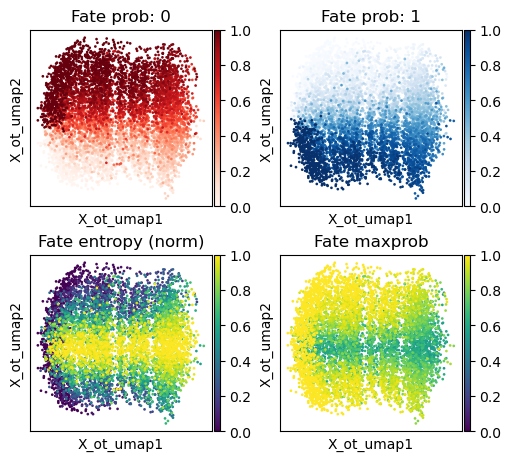

(<Figure size 500x450 with 8 Axes>,
 array([[<Axes: title={'center': 'Fate prob: 0'}, xlabel='X_ot_umap1', ylabel='X_ot_umap2'>,
         <Axes: title={'center': 'Fate prob: 1'}, xlabel='X_ot_umap1', ylabel='X_ot_umap2'>],
        [<Axes: title={'center': 'Fate entropy (norm)'}, xlabel='X_ot_umap1', ylabel='X_ot_umap2'>,
         <Axes: title={'center': 'Fate maxprob'}, xlabel='X_ot_umap1', ylabel='X_ot_umap2'>]],
       dtype=object))

In [4]:
F, fate_names = terminal_fates_from_terminal_clusters(adata_hvg, terminal_cluster_key="traj_clusters", out_key="terminal_fate_probs_traj")
fate_umap_2x2_scanpy(adata_hvg, size=15, umap_basis=key_out)

/new-stg/home/alex/miniconda3/envs/wot2/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


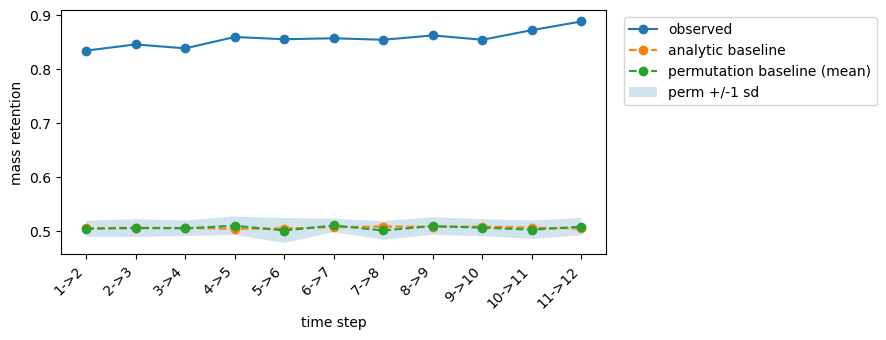

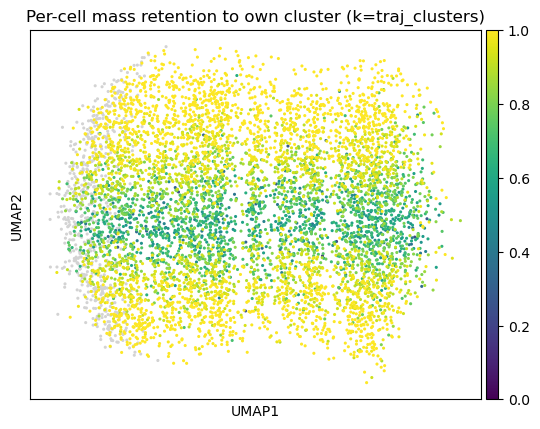

In [5]:
out = mass_retention_plots_and_umap(adata_hvg, T_pruned, 
                                    cluster_key="traj_clusters", 
                                    n_reps=50, clusters_to_plot=["0","1"], 
                                    umap_basis="umap", size=20)

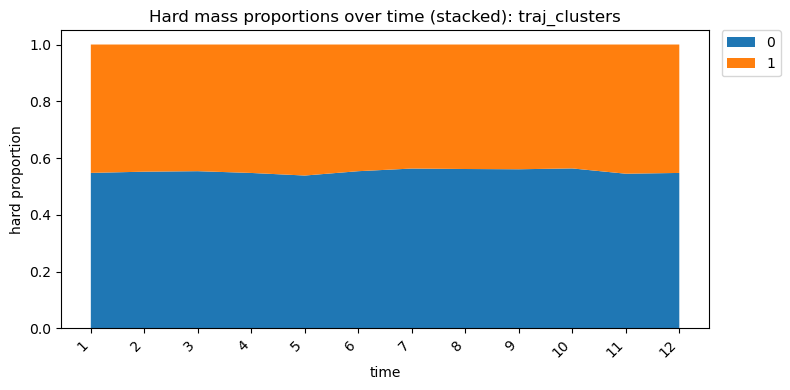

In [6]:
PlotHardClusterMassProportionsOverTime(adata_hvg)

# Visualize on original UMAP

In [7]:
tmp = sc.read_h5ad('../output/adata_hvg.1e4-variant.chk0.h5ad')
adata_hvg.obsm['X_umap_original'] = tmp.obsm['X_umap'].copy()

sc.tl.leiden(tmp, resolution=0.3)
adata_hvg.obs['leiden'] = tmp.obs['leiden'].copy()

In [8]:
adata = sc.read_h5ad('../output/adata_full.1e4-variant.chk0.h5ad')

adata.obs = adata_hvg.obs.copy()
adata.obsm = adata_hvg.obsm.copy()
adata.obsp = adata_hvg.obsp.copy()
adata.uns = adata_hvg.uns.copy()

adata.write_h5ad('../output/adata_full.1e4-variant.chk1.h5ad')
adata_hvg.write_h5ad('../output/adata_hvg.1e4-variant.chk1.h5ad')